In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [4]:
df_anual_temporada = pd.read_parquet("../data/processed/datos_meteo_Valencia_91-25(year).parquet")
df_anual_temporada.head()

,temp_mar_media (Cº),temp_media_anual (Cº),temp_max_absoluta (Cº),temp_min_absoluta (Cº),dias_temp_>30,precipitacion_total (mm),precip_max_diaria (mm),dias_lluvia_>10mm,dias_lluvia_>30mm,dias_lluvia_total,dias_granizo_total,dias_tormenta_total,humedad_media (%),presion_media (hPa),presion_minima_anual (hPa),viento_racha_maxima (km/h),viento_velocidad_media (km/h)
año,,,,,,,,,,,,,,,,,
1991,18.6,17.5,36.7,0.4,53,698.4,78.2,18,5,98,1,25,70.6,1015.3,984.3,52.9,14.8
1992,18.4,17.6,36.2,2.0,40,450.9,65.8,11,5,98,1,13,70.0,1015.9,990.0,63.5,14.7
1993,18.2,17.3,37.2,2.0,30,400.1,59.5,10,3,87,2,23,71.0,1015.3,992.2,52.2,14.5
1994,19.3,18.8,42.5,1.0,66,350.9,55.5,11,2,73,2,16,68.4,1015.1,986.7,49.9,15.0
1995,19.1,18.8,36.0,3.0,49,260.7,32.7,8,1,82,1,23,67.9,1014.8,995.1,57.3,15.5


In [ ]:
df_anual_temporada['temp_mar_rolling'] = df_anual_temporada['temp_mar_media (Cº)'].rolling(window=5, min_periods=1).mean()
df_anual_temporada['temp_aire_rolling'] = df_anual_temporada['temp_media_anual (Cº)'].rolling(window=5, min_periods=1).mean()

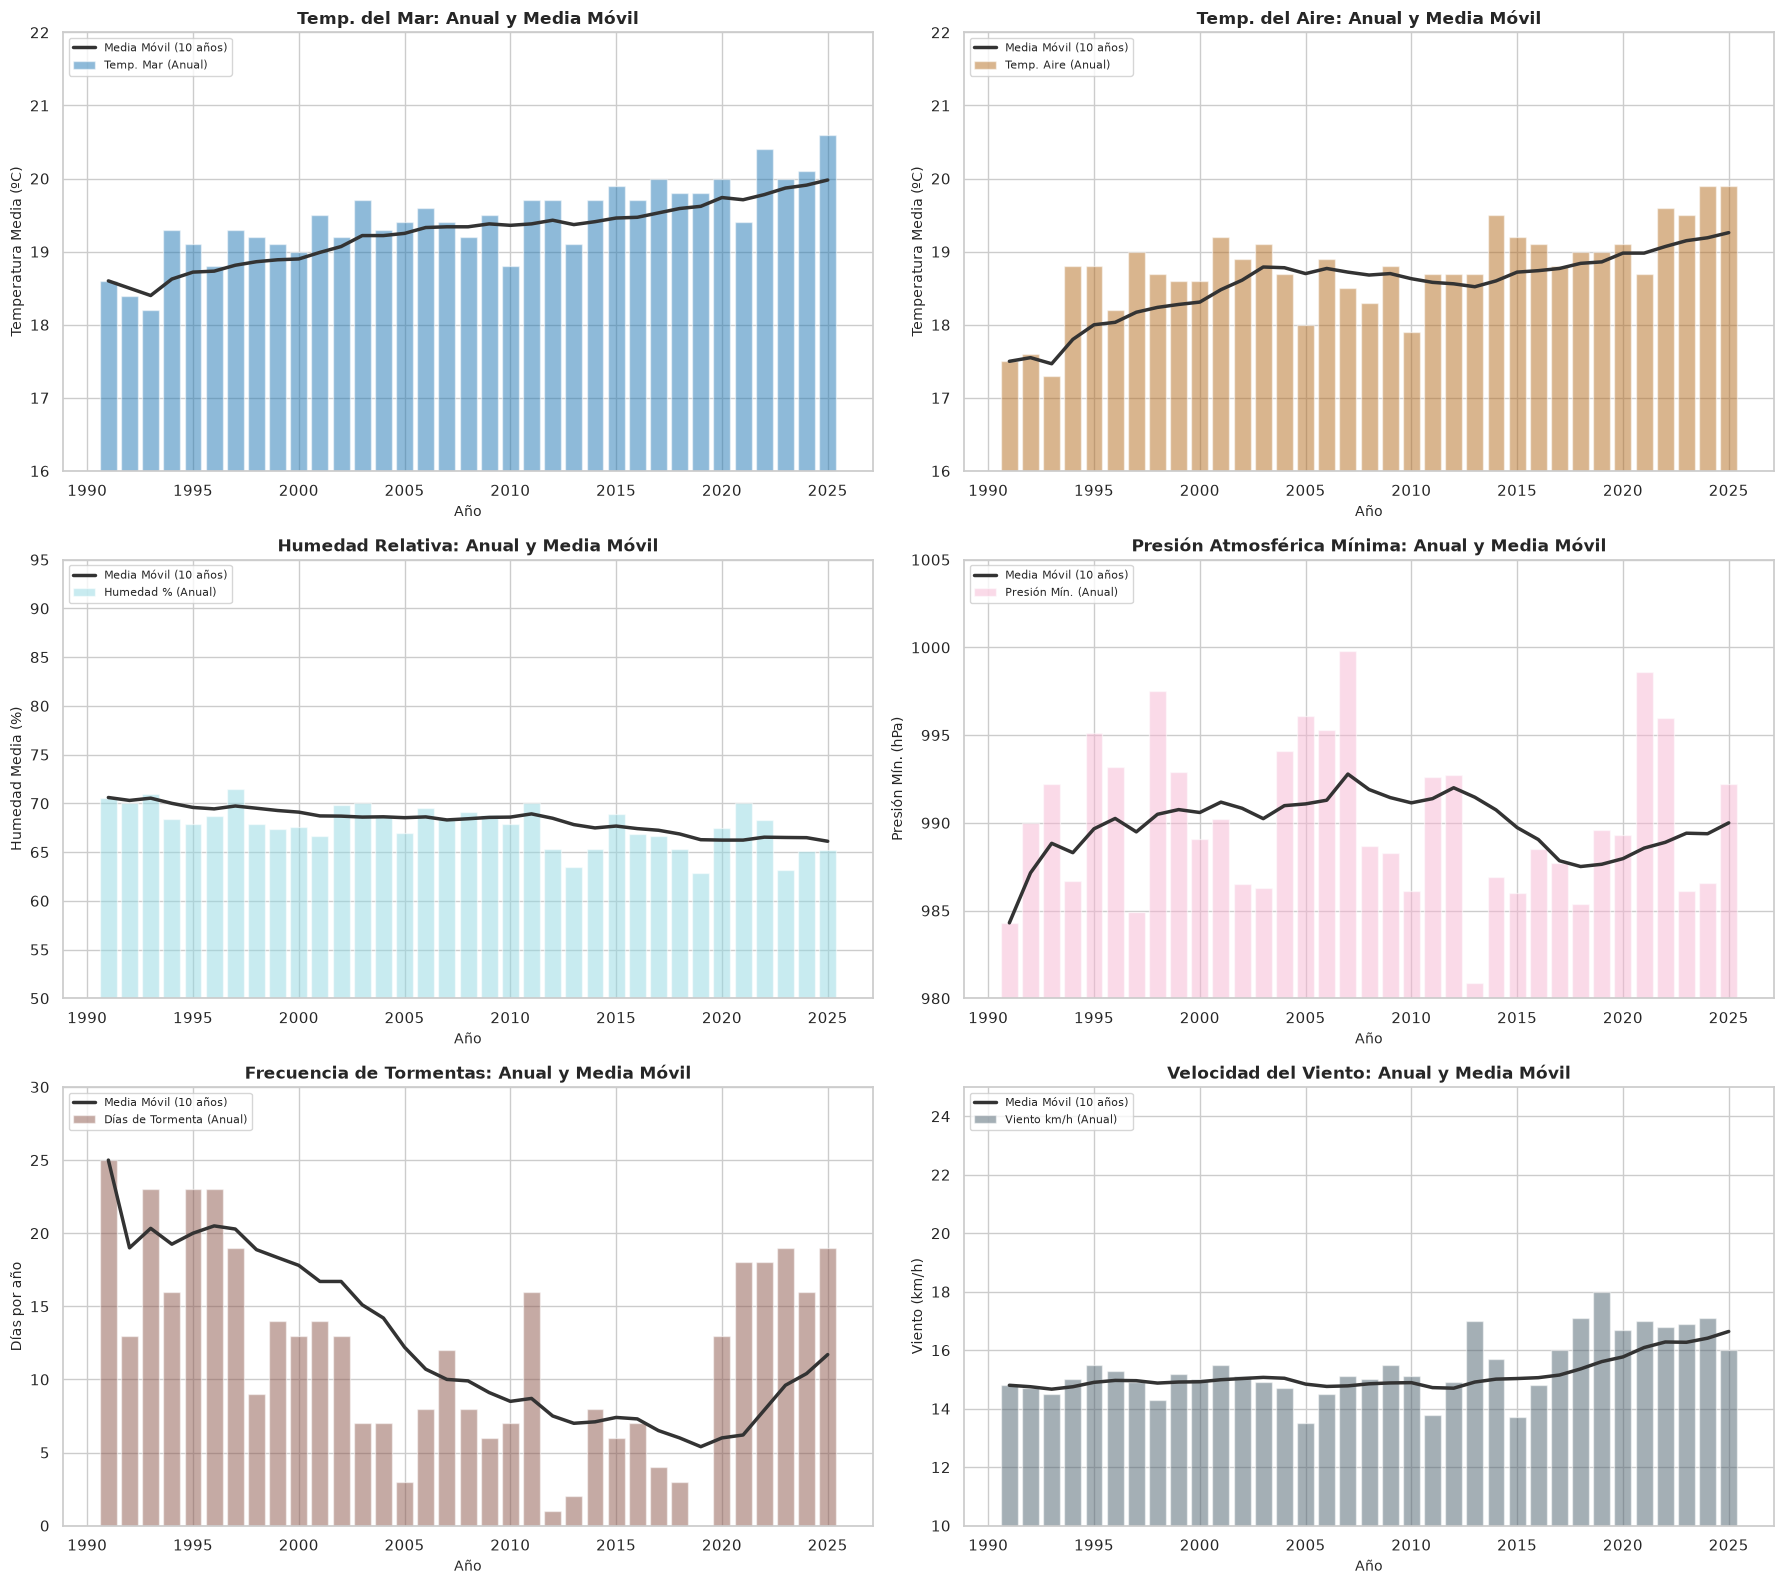

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos la configuración de los 12 paneles basada en tus variables decenales
variables_rolling = [
    {
        'col_anual': 'temp_mar_media (Cº)',
        'color': '#1f77b4',
        'label_bar': 'Temp. Mar (Anual)',
        'titulo': 'Temp. del Mar: Anual y Media Móvil',
        'ylabel': 'Temperatura Media (ºC)',
        'ylim': (16, 22)
    },
    {
        'col_anual': 'temp_media_anual (Cº)',
        'color': '#b46c1f',
        'label_bar': 'Temp. Aire (Anual)',
        'titulo': 'Temp. del Aire: Anual y Media Móvil',
        'ylabel': 'Temperatura Media (ºC)',
        'ylim': (16, 22)
    },
    {
        'col_anual': 'humedad_media (%)',
        'color': '#93d9e3',
        'label_bar': 'Humedad % (Anual)',
        'titulo': 'Humedad Relativa: Anual y Media Móvil',
        'ylabel': 'Humedad Media (%)',
        'ylim': (50, 95)
    },
    {
        'col_anual': 'presion_minima_anual (hPa)',
        'color': '#f7b6d2',
        'label_bar': 'Presión Mín. (Anual)',
        'titulo': 'Presión Atmosférica Mínima: Anual y Media Móvil',
        'ylabel': 'Presión Mín. (hPa)',
        'ylim': (980, 1005)
    },
    {
        'col_anual': 'dias_tormenta_total',
        'color': '#8c564b',
        'label_bar': 'Días de Tormenta (Anual)',
        'titulo': 'Frecuencia de Tormentas: Anual y Media Móvil',
        'ylabel': 'Días por año',
        'ylim': (0, 30)
    },
    {
        'col_anual': 'viento_velocidad_media (km/h)',
        'color': '#4b606d',
        'label_bar': 'Viento km/h (Anual)',
        'titulo': 'Velocidad del Viento: Anual y Media Móvil',
        'ylabel': 'Viento (km/h)',
        'ylim': (10, 25)
    }
]
# 2. Creamos la figura con una cuadrícula de 3 filas x 2 columnas
fig, axes = plt.subplots(3, 2, figsize=(18, 16))
axes = axes.flatten()  # Aplanamos el array para recorrerlo fácilmente con el bucle
sns.set_theme(style="whitegrid")

# 3. Bucle para calcular la media móvil y pintar cada panel automáticamente
for i, cfg in enumerate(variables_rolling):
    ax = axes[i]
    col = cfg['col_anual']
    
    # Calculamos la media móvil directamente en el DataFrame
    col_rolling = f"{col}_rolling"
    df_anual_temporada[col_rolling] = df_anual_temporada[col].rolling(window=10, min_periods=1).mean()
    
    # Gráfico de barras anuales (con transparencia)
    ax.bar(
        df_anual_temporada.index, 
        df_anual_temporada[col], 
        width=0.8, 
        color=cfg['color'], 
        alpha=0.5, 
        label=cfg['label_bar']
    )
    
    # Línea de media móvil superpuesta
    ax.plot(
        df_anual_temporada.index, 
        df_anual_temporada[col_rolling], 
        color='#333333', 
        linewidth=2.5, 
        linestyle='-',
        label='Media Móvil (10 años)'
    )
    
    # Estética y límites de cada panel
    ax.set_title(cfg['titulo'], fontsize=12, fontweight='bold')
    ax.set_ylabel(cfg['ylabel'], fontsize=10)
    ax.set_xlabel("Año", fontsize=10)
    ax.set_ylim(cfg['ylim'])
    ax.ticklabel_format(style='plain', useOffset=False)
    ax.legend(frameon=True, facecolor='white', loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()